# TVML — Sensor selection on synthetic temporal graph signals

This demonstration uses **20 synthetic sensors** on a weighted small-world graph. TVML groups sensors by statistical and spectral signal features, then selects one high-topology-score sensor per cluster.

Paper: [Faghih Niresi, Qing, Zhao, and Fink, *Reliability Engineering & System Safety* (2026)](https://doi.org/10.1016/j.ress.2025.112153).

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

from tvml import TVML

## 1. Generate a sensor graph and time series

Sensor columns are in the same order as `graph.nodes()`.

In [2]:
np.random.seed(42)

N = 20
T = 500
num_sensors = 5

graph = nx.watts_strogatz_graph(n=N, k=4, p=0.2, seed=42)
for u, v in graph.edges():
    graph[u][v]["weight"] = 0.5 + np.random.rand()

t = np.linspace(0, 10, T)
data = np.zeros((T, N))
for i in range(N):
    frequency = 0.5 + 0.1 * (i % 5)
    phase = 0.2 * i
    data[:, i] = np.sin(2 * np.pi * frequency * t + phase) + 0.15 * np.random.randn(T)

## 2. Select sensors with TVML

The default topology score uses equal weights and z-score normalization for the five centrality/spectral-localization features.

In [3]:
selected_nodes, selected_indices = TVML(
    data=data,
    graph=graph,
    num_sensors=num_sensors,
    alpha=(0.2, 0.2, 0.2, 0.2, 0.2),
    normalization_topofeature=True,
    random_state=42,
    return_indices=True,
)

print("Selected sensor node labels:", selected_nodes)
print("Selected data column indices:", selected_indices)

Selected sensor node labels: [ 7 12 10 14 17]
Selected data column indices: [ 7 12 10 14 17]


## 3. Visualize the selected sensors

The first panel shows the graph with selected nodes highlighted; the second shows their example time series.

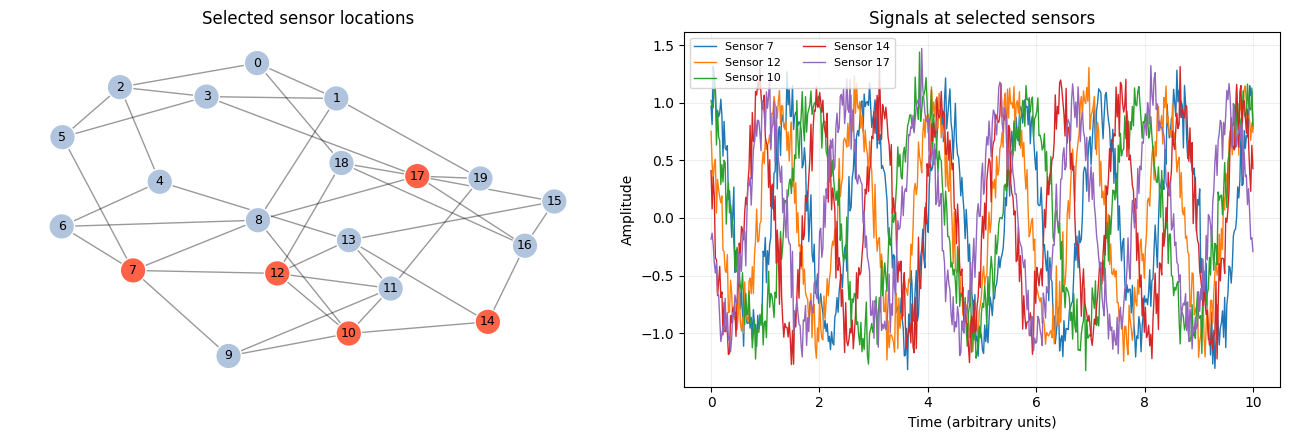

In [4]:
positions = nx.spring_layout(graph, seed=42)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

nx.draw_networkx_edges(graph, positions, ax=axes[0], alpha=0.4, width=1)
nx.draw_networkx_nodes(
    graph, positions, ax=axes[0],
    node_color=["tomato" if node in set(selected_nodes) else "lightsteelblue" for node in graph.nodes()],
    edgecolors="white", node_size=340,
)
nx.draw_networkx_labels(graph, positions, ax=axes[0], font_size=9)
axes[0].set_title("Selected sensor locations")
axes[0].axis("off")

for node_index in selected_indices:
    axes[1].plot(t, data[:, node_index], linewidth=1.0, label=f"Sensor {node_index}")
axes[1].set_title("Signals at selected sensors")
axes[1].set_xlabel("Time (arbitrary units)")
axes[1].set_ylabel("Amplitude")
axes[1].legend(fontsize=8, ncol=2)
axes[1].grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Alternative edge-weight interpretation

By default, weighted betweenness treats edge `weight` as a **path length**. To treat larger weights as **stronger/shorter connections** (the convention used for harmonic centrality), pass `betweenness_weight="distance"`. Selections may differ.

```python
other_nodes = TVML(data, graph, num_sensors=5, betweenness_weight="distance")
print(other_nodes)
```